
# How Long Will the Battery Last?

## 1. Project Overview

**Course:** AI255TBD – Edge AI, Module 1  
**Team:** Team 13  
**Project Type:** Supervised Machine Learning – Regression

### 1.1 Project Objective

The objective of this project is to develop a neural network that predicts the remaining battery life of a smart doorbell in days using five sensor input features.

The model will be trained using the Team 13 dataset. After training and evaluation, the selected model will be saved and integrated into an API hosted through GitHub Codespaces.

### 1.2 Problem Statement

Smart doorbells rely on batteries to operate continuously. Their remaining battery life can be influenced by several factors, including battery voltage, operating temperature, daily usage, Wi-Fi signal strength and device age.

The objective is to analyse these sensor readings and develop a machine learning model capable of estimating the number of days remaining before the battery needs replacement.

### 1.3 Input Features

The model uses the following five input features:

| Feature | Description | Unit |
|---|---|---|
| `battery_v` | Battery voltage | Volts (V) |
| `temp_c` | Operating temperature | Degrees Celsius (°C) |
| `rings_per_day` | Number of rings per day | Rings/day |
| `wifi_rssi_dbm` | Received Wi-Fi signal strength | dBm |
| `age_months` | Age of the device | Months |

### 1.4 Target Variable

**Target:** `days_left`

The target represents the estimated remaining battery life of the smart doorbell, measured in days.

### 1.5 Machine Learning Problem

This project is a **Supervised Regression Problem**.

- **Supervised learning:** The training dataset contains input features along with their corresponding target values.
- **Regression:** The model predicts a continuous numerical value representing the remaining battery life in days.

The neural network learns relationships between the five sensor features and the target variable `days_left`.

### 1.6 Dataset

The project uses the Team 13 training dataset:

`data/team_13_train.csv`

All dataset analysis, preprocessing, model training and evaluation will be based on this dataset.



# 2. Dataset Understanding and Inspection

## 2.1 Loading the Dataset

The first step in dataset analysis is loading the Team 13 training dataset into a Pandas DataFrame.

The dataset is stored in CSV (Comma-Separated Values) format. Pandas provides the `read_csv()` function to read the CSV file and represent its contents in a structured tabular format.

**Dataset path:** `data/team_13_train.csv`

**Objective:**
- Load the Team 13 dataset.
- Store the dataset in a Pandas DataFrame.
- Verify that the dataset has been loaded successfully.

The loaded DataFrame will be used for subsequent dataset inspection, statistical analysis, exploratory data analysis and preprocessing.


In [2]:

import pandas as pd

# Load the Team 13 training dataset
df = pd.read_csv("data/team_13_train.csv")

# Display the first five records
df.head()


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
0,3.767,18.2,17,-85,35,19.1
1,4.184,24.3,4,-63,15,221.7
2,3.585,18.7,16,-50,35,14.8
3,3.480,10.0,11,-56,3,10.9
4,3.366,28.7,10,-47,0,2.6



### 2.1.1 Dataset Loading — Observations and Results

The Team 13 training dataset was successfully loaded into a Pandas DataFrame using the `read_csv()` function.

The `df.head()` function was used to display the first five records.

**Observations:**

1. The dataset contains the five expected input features: `battery_v`, `temp_c`, `rings_per_day`, `wifi_rssi_dbm` and `age_months`.
2. The target variable `days_left` is also present.
3. The displayed records contain numerical sensor readings and their corresponding target values.
4. Wi-Fi RSSI readings are represented using negative values.
5. The displayed records show variation in sensor readings and predicted target values.

**Conclusion:**

The dataset was successfully loaded, and the expected input features and target variable are present. The DataFrame is ready for further structural and statistical inspection.

The complete dataset dimensions, data types, missing values and other data-quality characteristics will be examined in the subsequent steps.



## 2.2 Dataset Dimensions, Columns and Data Types

After loading the Team 13 dataset, the next step is to inspect its overall structure.

This analysis focuses on understanding the dimensions of the dataset, identifying its columns, examining the data types and checking the structural information of the DataFrame.

**Objectives:**

1. Determine the total number of observations (rows).
2. Determine the total number of variables (columns).
3. Identify all column names.
4. Examine the data type of each column.
5. Inspect the overall DataFrame structure and memory usage.

These checks help verify that the dataset is structurally suitable for further statistical analysis and machine learning preprocessing.


In [6]:

# 1. Display dataset dimensions
print("Dataset Dimensions:")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

# 2. Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Display dataset structure and data types
print("\nDataset Information:")
df.info()


Dataset Dimensions:
Rows: 2000
Columns: 6

Column Names:
['battery_v', 'temp_c', 'rings_per_day', 'wifi_rssi_dbm', 'age_months', 'days_left']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_v      2000 non-null   float64
 1   temp_c         2000 non-null   float64
 2   rings_per_day  2000 non-null   int64  
 3   wifi_rssi_dbm  2000 non-null   int64  
 4   age_months     2000 non-null   int64  
 5   days_left      2000 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 93.9 KB



### 2.2.1 Dataset Structure — Observations and Results

The Team 13 dataset was inspected using the Pandas `shape`, `columns` and `info()` properties and methods.

**1. Dataset Dimensions**

- Total observations: 2,000 rows.
- Total variables: 6 columns.
- The dataset contains five input features and one target variable.

**2. Column Verification**

The following six columns were identified:

- `battery_v`
- `temp_c`
- `rings_per_day`
- `wifi_rssi_dbm`
- `age_months`
- `days_left`

All expected input features and the target variable are present.

**3. Data Types**

The dataset contains:

- Three `float64` columns: `battery_v`, `temp_c` and `days_left`.
- Three `int64` columns: `rings_per_day`, `wifi_rssi_dbm` and `age_months`.

All six columns are stored as numerical data types.

**4. Non-Null Entries**

Each column contains 2,000 non-null entries. No missing values are indicated by the initial DataFrame information output.

This observation will be verified separately during the missing-value analysis.

**5. Memory Usage**

The DataFrame reports a memory usage of approximately 93.9 KB.

**Conclusion:**

The dataset contains 2,000 observations and six numerical columns. All expected input features and the target variable are present, and their data types are suitable for numerical analysis.

The initial structural inspection indicates that the dataset is ready for further data-quality checks and statistical analysis.



## 2.3 Missing Value Analysis

Missing value analysis is performed to identify whether any observations contain incomplete information.

Missing values can affect statistical calculations, data preprocessing and machine learning model training.

**Objectives:**

1. Identify missing values in each column.
2. Calculate the number of missing entries per column.
3. Determine the total number of missing values in the dataset.
4. Identify whether any columns contain incomplete observations.

This analysis helps determine whether missing-value handling is required before further data processing.


In [7]:

# Check missing values in each column
print("Missing Values Per Column:")
print(df.isnull().sum())

# Calculate total missing values
total_missing = df.isnull().sum().sum()

print("\nTotal Missing Values in Dataset:")
print(total_missing)

# Calculate missing value percentage per column
print("\nMissing Value Percentage Per Column:")
print((df.isnull().mean() * 100).round(2))


Missing Values Per Column:
battery_v        0
temp_c           0
rings_per_day    0
wifi_rssi_dbm    0
age_months       0
days_left        0
dtype: int64

Total Missing Values in Dataset:
0

Missing Value Percentage Per Column:
battery_v        0.0
temp_c           0.0
rings_per_day    0.0
wifi_rssi_dbm    0.0
age_months       0.0
days_left        0.0
dtype: float64



### 2.3.1 Missing Value Analysis — Observations and Results

Missing-value analysis was performed using Pandas `isnull()` to identify incomplete entries in the dataset.

**1. Missing Values Per Column**

The analysis identified zero missing values in all six columns:

- `battery_v`: 0
- `temp_c`: 0
- `rings_per_day`: 0
- `wifi_rssi_dbm`: 0
- `age_months`: 0
- `days_left`: 0

**2. Total Missing Values**

The total number of missing values across the entire dataset is 0.

**3. Missing Value Percentage**

All six columns have a missing-value percentage of 0.0%.

**Conclusion:**

The Team 13 dataset contains no missing or null entries according to the Pandas missing-value check. Therefore, no missing-value imputation or row removal is required at this stage.

However, the absence of missing values does not guarantee that all sensor readings are valid. Further data-quality checks will be performed to investigate duplicate records and potentially suspicious sensor values.



## 2.4 Duplicate Record Analysis

Duplicate analysis is performed to identify whether the dataset contains repeated observations.

An exact duplicate occurs when all column values in a row match another row.

**Objectives:**

1. Identify exact duplicate records across all columns.
2. Calculate the total number of duplicate rows.
3. Determine the percentage of duplicate records in the dataset.
4. Assess whether duplicate records require further investigation or removal.

Duplicate records can influence statistical analysis and model evaluation, particularly when repeated observations are distributed across training and validation datasets.

No records will be removed automatically during this inspection.


In [8]:

# Identify exact duplicate records
duplicate_count = df.duplicated().sum()

# Calculate duplicate percentage
duplicate_percentage = (duplicate_count / len(df)) * 100

# Display results
print("Duplicate Record Analysis:")
print(f"Total records: {len(df)}")
print(f"Duplicate records: {duplicate_count}")
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

# Display duplicate rows, if any
print("\nDuplicate Records:")
display(df[df.duplicated()])


Duplicate Record Analysis:
Total records: 2000
Duplicate records: 0
Duplicate percentage: 0.00%

Duplicate Records:


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left



### 2.4.1 Observations and Conclusion

- Total records: 2,000.
- Exact duplicate records: 0.
- Duplicate percentage: 0.00%.

**Conclusion:** No exact duplicate rows were identified across the six columns. Therefore, no records require removal due to exact duplication.



## 2.5 Descriptive Statistical Analysis

Descriptive statistics are calculated to understand the numerical characteristics and variability of the dataset.

The analysis includes count, mean, standard deviation, minimum, maximum and quartiles for each numerical column.

**Objective:** Understand the central tendency, spread and range of sensor readings and the target variable.


In [9]:

# Calculate descriptive statistics for all numerical columns
print("Descriptive Statistical Summary:")
display(df.describe())


Descriptive Statistical Summary:


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,3.756825,27.165150,7.938500,-66.298000,18.205000,75.554550
std,0.371475,11.936212,5.631303,12.547108,10.661745,67.287199
min,0.000000,-127.000000,0.000000,-88.000000,0.000000,0.200000
25%,3.560000,22.975000,4.000000,-76.000000,9.000000,19.975000
50%,3.772000,27.900000,7.000000,-66.000000,18.000000,59.450000
75%,3.985250,32.400000,11.000000,-56.000000,27.000000,114.400000
max,4.200000,46.000000,44.000000,0.000000,36.000000,367.200000



### 2.5.1 Observations and Conclusion

- Dataset contains 2,000 observations across six numerical columns.
- Mean battery voltage: 3.757 V.
- Mean temperature: 27.17°C.
- Mean daily usage: 7.94 rings.
- Mean device age: 18.21 months.
- Mean remaining battery life: 75.55 days.
- `days_left` has a standard deviation of 67.29 days.
- The minimum battery voltage (0 V) and temperature (-127°C) require further investigation.

**Conclusion:** The descriptive statistics reveal variation across sensor readings and the target variable. Potentially suspicious minimum values were identified and will be investigated during subsequent data-quality analysis.



## 2.6 Unique Values and Value Range Analysis

This analysis examines the distinct values and numerical ranges of each dataset column.

**Objectives:**
- Count unique values in each column.
- Identify minimum and maximum values.
- Examine distinct readings in integer-based features.
- Identify unusual values for further investigation.


In [10]:

# 1. Unique value count for each column
print("Unique Value Counts:")
print(df.nunique())

# 2. Minimum and maximum values
print("\nValue Ranges:")
print(df.agg(["min", "max"]).T)

# 3. Display distinct values in integer-based columns
integer_columns = df.select_dtypes(include="int64").columns

print("\nUnique Values in Integer Columns:")
for col in integer_columns:
    print(f"\n{col}:")
    print(sorted(df[col].unique()))

# 4. Display sample unique values in decimal-based columns
float_columns = df.select_dtypes(include="float64").columns

print("\nSample Unique Values in Float Columns:")
for col in float_columns:
    values = sorted(df[col].unique())
    print(f"\n{col}: {values[:10]}")
    print(f"Total unique values: {len(values)}")


Unique Value Counts:
battery_v         777
temp_c            316
rings_per_day      37
wifi_rssi_dbm      45
age_months         37
days_left        1190
dtype: int64

Value Ranges:
                 min    max
battery_v        0.0    4.2
temp_c        -127.0   46.0
rings_per_day    0.0   44.0
wifi_rssi_dbm  -88.0    0.0
age_months       0.0   36.0
days_left        0.2  367.2

Unique Values in Integer Columns:

rings_per_day:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(36), np.int64(44)]

wifi_rssi_dbm:
[np.int64(-88), np.int64(-87), np.int64(-86), n


### 2.6.1 Observations and Conclusion

- `battery_v`: 777 unique values, ranging from 0 to 4.2 V.
- `temp_c`: 316 unique values, ranging from -127°C to 46°C.
- `rings_per_day`: 37 unique values, ranging from 0 to 44.
- `wifi_rssi_dbm`: 45 unique values, ranging from -88 to 0 dBm.
- `age_months`: 37 unique values, ranging from 0 to 36 months.
- `days_left`: 1,190 unique values, ranging from 0.2 to 367.2 days.

**Conclusion:** The dataset contains varying numbers of distinct values across its features. The minimum battery voltage of 0 V and temperature of -127°C are potential sensor anomalies requiring further investigation.



## 2.7 Quartiles, Skewness and Distribution Analysis

This analysis examines the spread and shape of numerical feature distributions.

**Objectives:**
- Examine Q1, median and Q3.
- Calculate skewness for each numerical column.
- Visualise feature distributions using histograms.
- Identify potentially skewed distributions and unusual patterns.


Quartile Analysis:


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
0.25,3.56000,22.975,4.0,-76.0,9.0,19.975
0.50,3.77200,27.900,7.0,-66.0,18.0,59.450
0.75,3.98525,32.400,11.0,-56.0,27.0,114.400



Skewness Analysis:
battery_v       -5.620
temp_c          -8.580
rings_per_day    1.411
wifi_rssi_dbm    0.340
age_months       0.001
days_left        1.174
dtype: float64


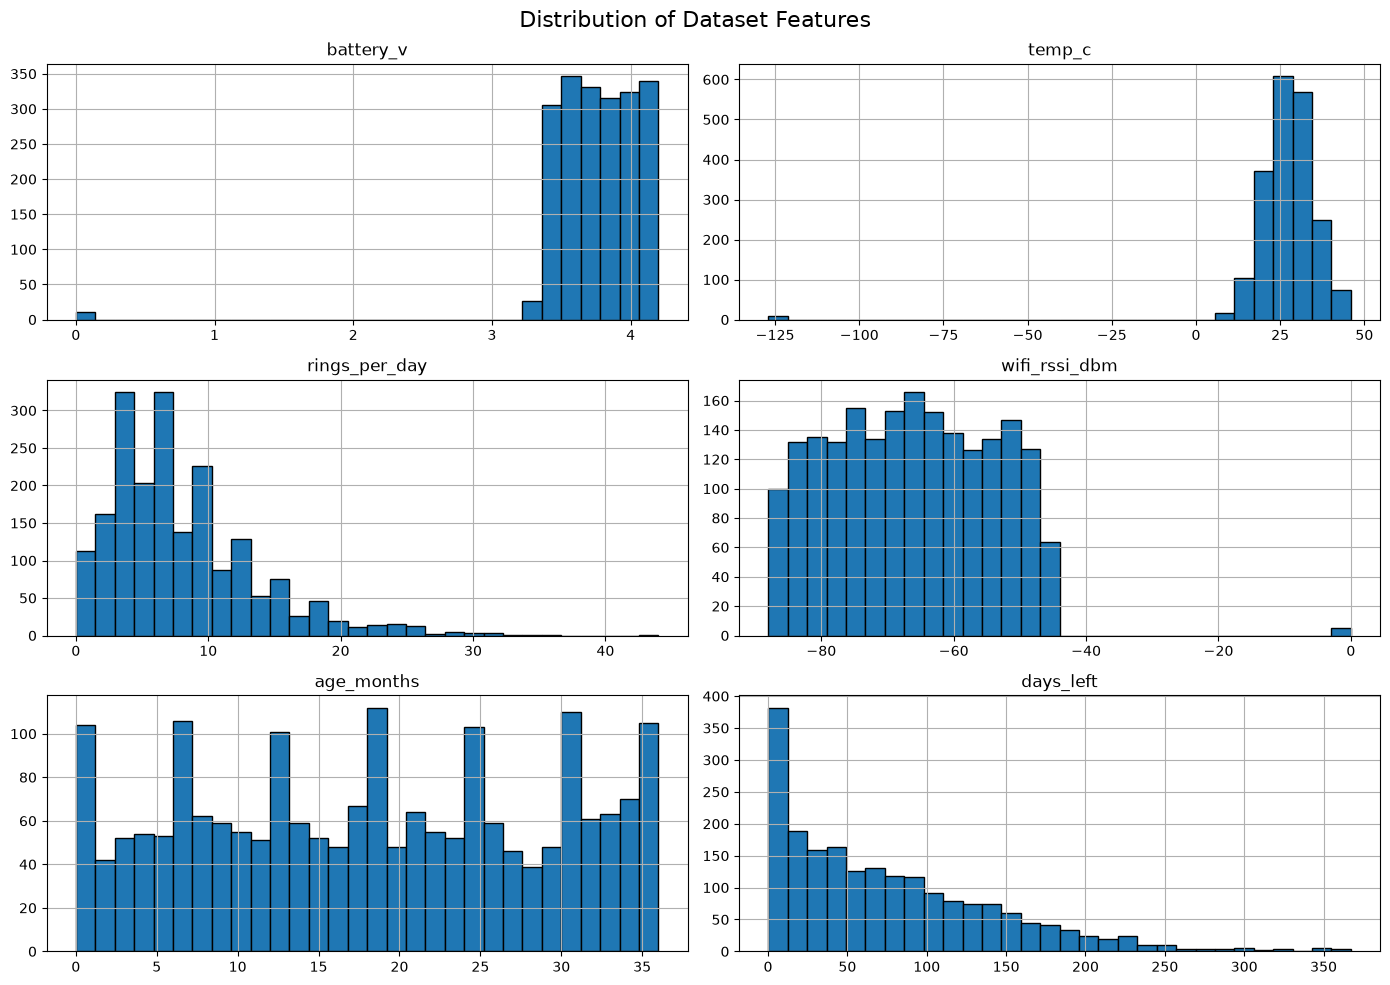

In [11]:

import matplotlib.pyplot as plt

# 1. Calculate quartiles
print("Quartile Analysis:")
display(df.quantile([0.25, 0.50, 0.75]))

# 2. Calculate skewness
print("\nSkewness Analysis:")
print(df.skew().round(3))

# 3. Plot distributions of all numerical columns
df.hist(figsize=(14, 10), bins=30, edgecolor="black")
plt.suptitle("Distribution of Dataset Features", fontsize=16)
plt.tight_layout()
plt.show()



### 2.7.1 Observations and Conclusion

- Battery voltage and temperature show strong negative skewness (-5.620 and -8.580).
- Daily usage and remaining battery life show positive skewness (1.411 and 1.174).
- Wi-Fi RSSI has slight positive skewness (0.340).
- Device age is approximately symmetric (0.001).
- Histograms reveal isolated values at 0 V, -127°C and 0 dBm.
- Remaining battery life has a long right tail.

**Conclusion:** The feature distributions exhibit different patterns of variability and skewness. Potential sensor anomalies were identified in battery voltage, temperature and Wi-Fi RSSI for further investigation.



## 2.8 Initial Data-Quality Assessment

This section consolidates the findings from the dataset inspection and statistical analysis to identify potential data-quality concerns.

**Objectives:**
- Summarise missing-value and duplicate checks.
- Identify unusual sensor readings and value ranges.
- Review distribution and skewness patterns.
- Record potential issues requiring further investigation during preprocessing.


In [22]:

# Consolidated data-quality assessment

quality_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique(),
    "Minimum": df.min(),
    "Maximum": df.max(),
    "Skewness": df.skew().round(3)
})

print("Initial Data Quality Summary:")
display(quality_summary)

print("\nTotal Duplicate Records:", df.duplicated().sum())
print("Total Missing Values:", df.isnull().sum().sum())


Initial Data Quality Summary:


,Missing Values,Unique Values,Minimum,Maximum,Skewness
battery_v,0,777,0.0,4.2,-5.620
temp_c,0,316,-127.0,46.0,-8.580
rings_per_day,0,37,0.0,44.0,1.411
wifi_rssi_dbm,0,45,-88.0,0.0,0.340
age_months,0,37,0.0,36.0,0.001
days_left,0,1190,0.2,367.2,1.174



Total Duplicate Records: 0
Total Missing Values: 0



### 2.8.1 Observations and Conclusion

- Dataset contains 2,000 records and six numerical columns.
- No missing values or exact duplicate records were identified.
- Potential anomalies include battery voltage of 0 V, temperature of -127°C and Wi-Fi RSSI of 0 dBm.
- Battery voltage and temperature exhibit strong negative skewness.
- Daily usage and remaining battery life exhibit positive skewness.

**Conclusion:** The dataset is structurally complete but contains potentially suspicious sensor readings and skewed distributions. These observations will guide the subsequent data-cleaning and preprocessing stages.


### 3.1 Correlation Analysis

Correlation analysis is used to examine the strength and direction of linear relationships between numerical features. Pearson correlation coefficients are calculated to understand how the input features relate to the target variable, `days_left`.

In [23]:
# Calculate the Pearson correlation matrix
correlation_matrix = df.corr(method='pearson')

# Display the correlation matrix
display(correlation_matrix)

# Display correlation of all features with the target variable
target_correlation = correlation_matrix['days_left'].sort_values(
    ascending=False
)

print("Correlation with days_left:")
display(target_correlation)

,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
battery_v,1.000000,-0.015116,0.027365,-0.025096,-0.011235,0.464509
temp_c,-0.015116,1.000000,-0.047490,-0.046774,0.013489,-0.063449
rings_per_day,0.027365,-0.047490,1.000000,-0.019871,0.003793,-0.273241
wifi_rssi_dbm,-0.025096,-0.046774,-0.019871,1.000000,-0.005807,0.344635
age_months,-0.011235,0.013489,0.003793,-0.005807,1.000000,-0.220986
days_left,0.464509,-0.063449,-0.273241,0.344635,-0.220986,1.000000


Correlation with days_left:


days_left        1.000000
battery_v        0.464509
wifi_rssi_dbm    0.344635
temp_c          -0.063449
age_months      -0.220986
rings_per_day   -0.273241
Name: days_left, dtype: float64

### Correlation Analysis – Observations

- `battery_v` has the strongest positive correlation with `days_left` (0.4645).
- `wifi_rssi_dbm` shows a moderate positive correlation (0.3446).
- `rings_per_day` (-0.2732) and `age_months` (-0.2210) show weak negative correlations.
- `temp_c` (-0.0634) has a very weak negative linear relationship with the target.

**Conclusion:** Battery voltage has the strongest linear association with the remaining battery life in this dataset. However, all input features will be retained for further analysis because correlation alone cannot determine their predictive usefulness.

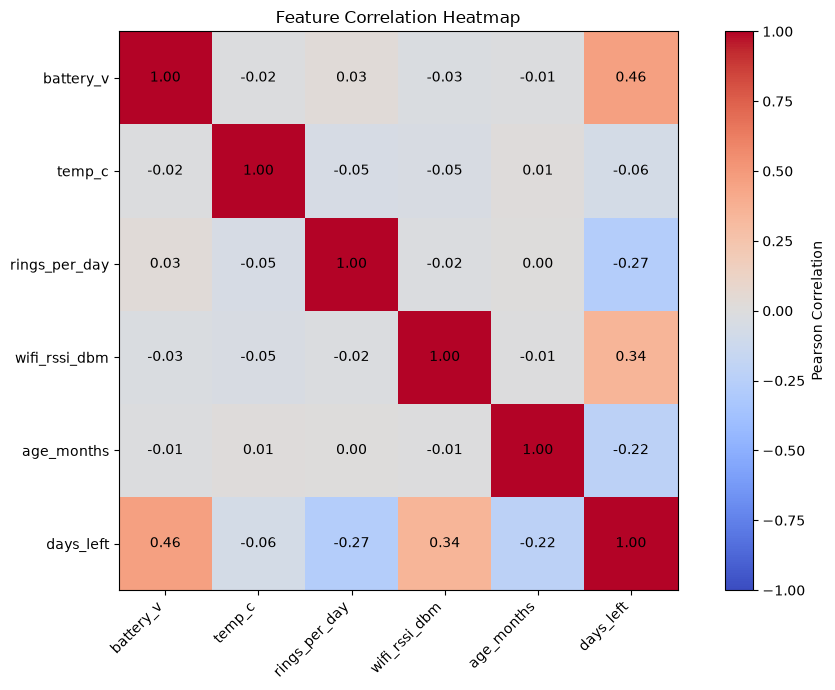

In [24]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 7))

plt.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)

plt.colorbar(label='Pearson Correlation')

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)

for i in range(len(correlation_matrix)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j, i,
            f'{correlation_matrix.iloc[i, j]:.2f}',
            ha='center',
            va='center'
        )

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

### Correlation Heatmap – Observations

- The heatmap visually confirms the Pearson correlation results.
- Battery voltage shows the strongest positive correlation with `days_left` (0.46).
- Wi-Fi signal strength shows a moderate positive correlation (0.34).
- Daily rings and battery age show negative correlations with the target.
- Temperature has a very weak linear relationship with the target.
- Most input features show very weak pairwise linear correlations with one another.

**Conclusion:** Battery voltage and Wi-Fi signal strength have the strongest positive linear associations with remaining battery life. The heatmap provides a visual overview of the relationships between all numerical features.

### 3.3 Feature vs Target Visualisation

In this step, we analyse the relationship between each input feature and the target variable, `days_left`, using scatter plots.

A scatter plot represents individual observations as points, with the input feature on the X-axis and `days_left` on the Y-axis.

This visualisation helps us:

- Understand how each input feature varies with the target variable.
- Identify positive, negative or nonlinear relationships.
- Observe clusters, unusual patterns and potential outliers.
- Compare visual patterns with the correlation results obtained earlier.

We will generate separate scatter plots for all five input features against `days_left`.

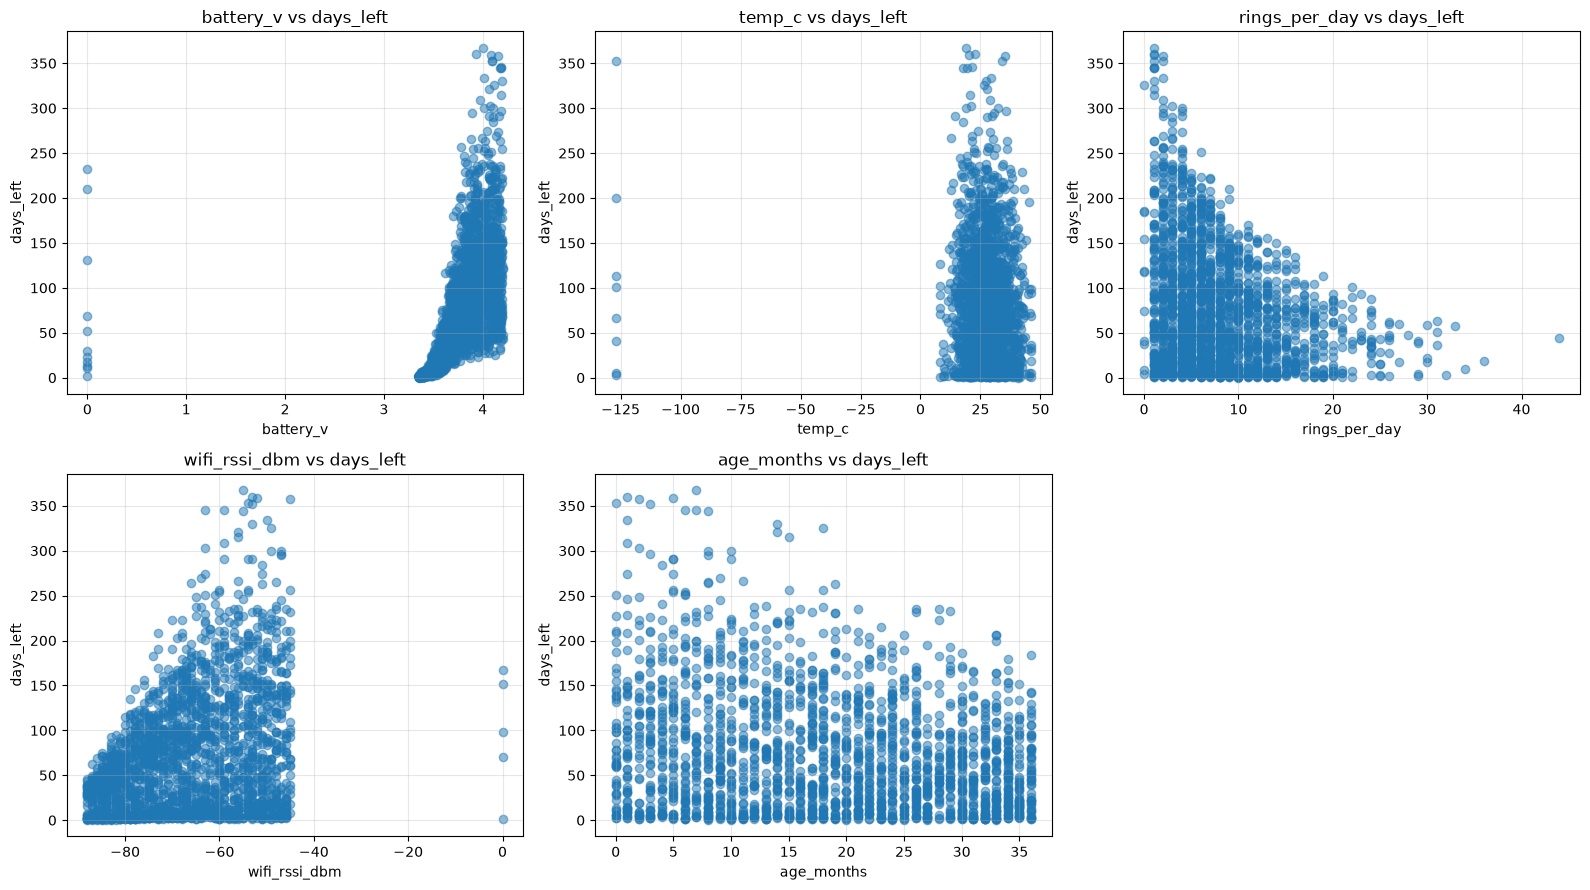

In [21]:
import matplotlib.pyplot as plt

# Input features
features = [
    'battery_v',
    'temp_c',
    'rings_per_day',
    'wifi_rssi_dbm',
    'age_months'
]

# Create scatter plots
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

for i, feature in enumerate(features):

    axes[i].scatter(
        df[feature],
        df['days_left'],
        alpha=0.5
    )

    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('days_left')
    axes[i].set_title(f'{feature} vs days_left')
    axes[i].grid(alpha=0.3)

# Hide unused subplot
axes[5].axis('off')

plt.tight_layout()
plt.show()

### Feature vs Target Visualisation – Observations

- **battery_v:** Shows a positive relationship with `days_left`. Higher voltage generally corresponds to more remaining days.
- **temp_c:** Shows a very weak relationship with the target, with no clear visual trend.
- **rings_per_day:** Shows a negative relationship. Higher daily ring counts generally correspond to fewer remaining days.
- **wifi_rssi_dbm:** Shows a positive relationship with the target.
- **age_months:** Shows a weak negative relationship. Older batteries generally tend to have fewer remaining days.

**Additional observations:**
- Unusual values were observed in `battery_v` (0), `temp_c` (-127) and `wifi_rssi_dbm` (0).
- The plots show considerable variation, suggesting that multiple features may contribute to battery-life prediction.

**Conclusion:** Battery voltage and Wi-Fi RSSI show visible positive relationships with remaining battery life, while daily rings and battery age show negative relationships. Temperature has little visible linear association with the target. Potential sensor anomalies will be investigated during the data-cleaning phase.

### 3.4 Pairwise Feature Relationship Analysis

In this step, we examine the relationships between the input features using a scatter matrix.

A scatter matrix displays scatter plots for pairs of numerical features and their individual distributions along the diagonal.

This analysis helps us:

- Identify relationships between input features.
- Observe possible clusters and patterns.
- Understand the distribution of individual features.
- Identify potential multicollinearity and unusual observations.

The target variable, `days_left`, is excluded because this step focuses on relationships among the input features.

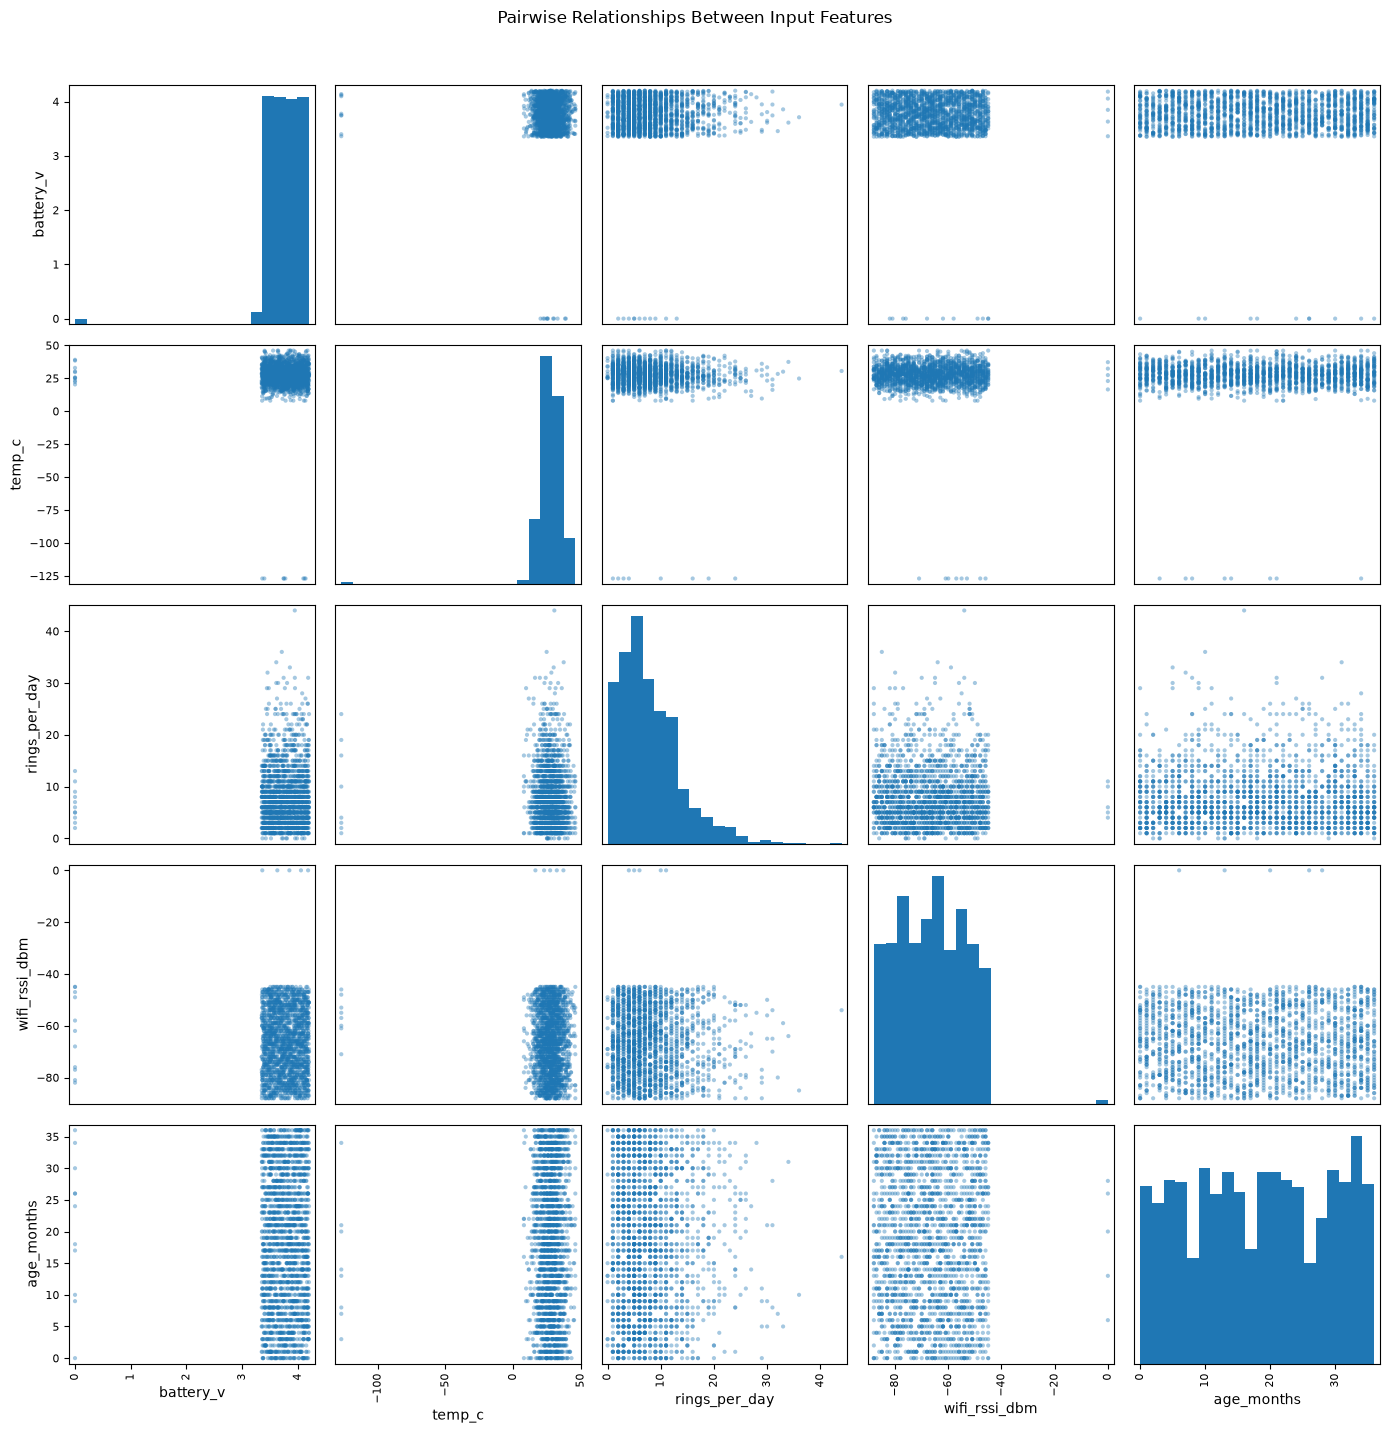

In [26]:
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix

# Select input features only
features_df = df[
    [
        'battery_v',
        'temp_c',
        'rings_per_day',
        'wifi_rssi_dbm',
        'age_months'
    ]
]

# Generate scatter matrix
scatter_matrix(
    features_df,
    figsize=(14, 14),
    diagonal='hist',
    alpha=0.4,
    hist_kwds={'bins': 20}
)

plt.suptitle(
    'Pairwise Relationships Between Input Features',
    y=1.02
)

plt.tight_layout()
plt.show()

### Pairwise Feature Relationship Analysis – Observations

- The diagonal histograms show the individual distributions of the five input features.
- `battery_v` and `temp_c` have most observations concentrated within their normal-looking ranges.
- `rings_per_day` shows a positively skewed distribution, with most observations having relatively low ring counts.
- `age_months` is distributed across the 0–36 month range.
- The pairwise scatter plots do not show strong linear relationships between the input features.
- The observations are consistent with the earlier correlation matrix, where most feature-to-feature correlations were close to zero.
- Unusual values such as battery voltage 0, temperature -127 and Wi-Fi RSSI 0 are also visible.

**Conclusion:** The pairwise analysis indicates that the input features have relatively weak linear relationships with one another. Potentially unusual sensor readings have been identified for further investigation during data cleaning.

### 3.5 Feature Relationship Interpretation

In this step, we interpret the findings obtained from correlation analysis, the correlation heatmap, feature-versus-target scatter plots and pairwise feature analysis.

The objective is to understand the relationship between each input feature and the target variable, `days_left`, and assess the potential usefulness of the features for battery-life prediction.

We will also examine the relationships among input features to identify any strong linear associations.

This interpretation will help guide subsequent preprocessing and model development decisions.

### Feature Relationship Interpretation – Observations

- `battery_v` shows the strongest positive linear relationship with `days_left` (0.4645).
- `wifi_rssi_dbm` shows the second strongest positive relationship (0.3446).
- `rings_per_day` (-0.2732) and `age_months` (-0.2210) show weak negative relationships with the target.
- `temp_c` (-0.0634) has a very weak linear relationship with the target.
- Pairwise analysis indicates that the input features have relatively weak linear relationships with one another.
- Scatter plots reveal considerable variation, indicating that individual features do not fully explain the target variable.

**Conclusion:** Battery voltage and Wi-Fi RSSI show stronger linear associations with remaining battery life. However, weaker correlations do not necessarily mean that other features are unimportant. All five input features will be retained for subsequent model experiments.

### 3.6 EDA Summary and Conclusion

Exploratory Data Analysis was performed to understand the dataset distributions, feature relationships and potential data-quality issues.

**Key Findings:**

1. **Dataset:** The dataset contains 2,000 records and five input features, with `days_left` as the target variable.
2. **Correlation:** Battery voltage (0.4645) has the strongest positive correlation with the target, followed by Wi-Fi RSSI (0.3446).
3. **Negative relationships:** Daily rings (-0.2732) and battery age (-0.2210) show weak negative correlations with the target.
4. **Temperature:** Temperature (-0.0634) shows a very weak linear relationship with the target.
5. **Feature relationships:** Pairwise analysis indicates relatively weak linear relationships among the input features.
6. **Potential anomalies:** Unusual values were identified in battery voltage (0), temperature (-127) and Wi-Fi RSSI (0).

**Overall Conclusion:**

EDA provided an understanding of the dataset's distributions, relationships and potential anomalies. All five input features will be retained for further model experiments. The identified unusual sensor readings will be investigated during the data-cleaning phase before model training.

## Phase 4 – Statistical Analysis and Feature Relationships

### 4.1 Distribution Analysis

In this step, we examine the statistical distributions of all input features and the target variable.

We use descriptive statistics, quartiles, interquartile range (IQR) and skewness to understand the central tendency, variability and distribution patterns of the data.

This analysis helps identify features with different scales, highly skewed distributions and potentially unusual observations that require further investigation.

In [27]:
# Calculate descriptive statistics
distribution_stats = df.describe().T

# Add IQR and skewness
distribution_stats['IQR'] = (
    distribution_stats['75%'] - distribution_stats['25%']
)

distribution_stats['Skewness'] = df.skew()

display(distribution_stats)

,count,mean,std,min,25%,50%,75%,max,IQR,Skewness
battery_v,2000.0,3.756825,0.371475,0.0,3.560,3.772,3.98525,4.2,0.42525,-5.619861
temp_c,2000.0,27.165150,11.936212,-127.0,22.975,27.900,32.40000,46.0,9.42500,-8.580419
rings_per_day,2000.0,7.938500,5.631303,0.0,4.000,7.000,11.00000,44.0,7.00000,1.411418
wifi_rssi_dbm,2000.0,-66.298000,12.547108,-88.0,-76.000,-66.000,-56.00000,0.0,20.00000,0.340094
age_months,2000.0,18.205000,10.661745,0.0,9.000,18.000,27.00000,36.0,18.00000,0.000714
days_left,2000.0,75.554550,67.287199,0.2,19.975,59.450,114.40000,367.2,94.42500,1.174124


### Distribution Analysis – Observations

- Battery voltage has a mean of 3.757 V and median of 3.772 V.
- Temperature has a mean of 27.165°C and median of 27.9°C.
- Daily ring counts show positive skewness (1.41).
- Wi-Fi RSSI has a relatively low positive skewness (0.34).
- Battery age is approximately symmetric, with skewness close to zero.
- `days_left` shows positive skewness (1.17), indicating a longer right tail.
- Battery voltage (-5.62) and temperature (-8.58) show strong negative skewness, potentially influenced by unusual sensor readings.

**Conclusion:** The features exhibit different distribution patterns and variability. Battery voltage and temperature contain highly unusual distribution characteristics that require further investigation during outlier and sensor-glitch analysis.

### 4.2 Outlier Investigation using IQR

The Interquartile Range (IQR) method is used to identify potential outliers in numerical features.

IQR represents the difference between the third quartile (Q3) and the first quartile (Q1).

The lower and upper boundaries are calculated using 1.5 times the IQR. Observations outside these boundaries are flagged as potential outliers.

This analysis helps identify extreme values that may require further investigation before data preprocessing and model training.

No observations will be removed or modified at this stage.

In [28]:
# Identify potential outliers using the IQR method

features = [
    'battery_v',
    'temp_c',
    'rings_per_day',
    'wifi_rssi_dbm',
    'age_months',
    'days_left'
]

outlier_results = []

for feature in features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    outlier_results.append({
        'Feature': feature,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': (len(outliers) / len(df)) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(3))

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,battery_v,2.922,4.623,11,0.55
1,temp_c,8.838,46.537,15,0.75
2,rings_per_day,-6.500,21.500,60,3.00
3,wifi_rssi_dbm,-106.000,-26.000,5,0.25
4,age_months,-18.000,54.000,0,0.00
5,days_left,-121.663,256.038,33,1.65


### IQR Outlier Investigation – Observations

The IQR method was applied to all five input features and the target variable.

- `battery_v`: 11 potential outliers (0.55%).
- `temp_c`: 15 potential outliers (0.75%).
- `rings_per_day`: 60 potential outliers (3.00%).
- `wifi_rssi_dbm`: 5 potential outliers (0.25%).
- `age_months`: No potential outliers detected.
- `days_left`: 33 potential outliers (1.65%).

The zero battery-voltage readings, -127°C temperature readings and zero Wi-Fi RSSI readings are particularly suspicious and require further investigation.

Higher daily ring counts and remaining-life values may represent unusual but valid observations.

**Conclusion:** The IQR method identified potential outliers across five of the six numerical columns. These observations will be investigated further before making any data-cleaning decisions. No records have been removed or modified.

### 4.3 Statistical Relationship Analysis using Spearman Correlation

In this step, Spearman rank correlation is used to examine relationships between numerical features and the target variable, `days_left`.

Unlike Pearson correlation, which measures linear relationships, Spearman correlation evaluates monotonic relationships using ranked values.

This analysis provides an additional understanding of feature relationships, particularly when the data contains skewed distributions or potential outliers.

The Spearman correlation results will be compared with the Pearson correlation results to identify similarities and differences in the relationships.

In [29]:
# Calculate Spearman correlation matrix
spearman_matrix = df.corr(method='spearman')

# Display the complete correlation matrix
display(spearman_matrix.round(4))

# Display correlation of features with the target
spearman_target = spearman_matrix['days_left'].sort_values(
    ascending=False
)

print("Spearman Correlation with days_left:")
display(spearman_target.round(4))

,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
battery_v,1.0000,-0.0225,0.0172,-0.0190,0.0021,0.7993
temp_c,-0.0225,1.0000,-0.0504,-0.0153,-0.0049,-0.0571
rings_per_day,0.0172,-0.0504,1.0000,-0.0156,-0.0059,-0.2263
wifi_rssi_dbm,-0.0190,-0.0153,-0.0156,1.0000,-0.0065,0.3169
age_months,0.0021,-0.0049,-0.0059,-0.0065,1.0000,-0.1757
days_left,0.7993,-0.0571,-0.2263,0.3169,-0.1757,1.0000


Spearman Correlation with days_left:


days_left        1.0000
battery_v        0.7993
wifi_rssi_dbm    0.3169
temp_c          -0.0571
age_months      -0.1757
rings_per_day   -0.2263
Name: days_left, dtype: float64

### Spearman Correlation Analysis – Observations

- `battery_v` shows a strong positive Spearman correlation with `days_left` (0.7993), considerably higher than its Pearson correlation (0.4645).
- `wifi_rssi_dbm` shows a moderate positive correlation (0.3169).
- `rings_per_day` (-0.2263) and `age_months` (-0.1757) show negative relationships with the target.
- `temp_c` (-0.0571) shows a very weak negative relationship.
- The difference between Pearson and Spearman correlation for battery voltage suggests a potentially nonlinear but monotonic relationship.

**Conclusion:** Spearman correlation provides additional evidence that battery voltage has a strong monotonic association with remaining battery life. The results will be considered during feature assessment and model development.

### 4.4 Feature Range Assessment

In this step, we examine the minimum, maximum and observed ranges of all input features and the target variable.

The purpose is to identify values that may fall outside plausible operating ranges or represent unusual sensor readings.

We will compare the observed values with the statistical findings from previous subtasks to identify potential data-quality issues.

These observations will help determine which values require further investigation during sensor-glitch detection and data cleaning.

No values will be modified or removed during this assessment.

In [30]:
# Examine the observed range of each feature

range_summary = pd.DataFrame({
    'Minimum': df.min(),
    'Maximum': df.max(),
    'Range': df.max() - df.min(),
    'Unique Values': df.nunique()
})

display(range_summary)

,Minimum,Maximum,Range,Unique Values
battery_v,0.0,4.2,4.2,777
temp_c,-127.0,46.0,173.0,316
rings_per_day,0.0,44.0,44.0,37
wifi_rssi_dbm,-88.0,0.0,88.0,45
age_months,0.0,36.0,36.0,37
days_left,0.2,367.2,367.0,1190


### Feature Range Assessment – Observations

- `battery_v` ranges from 0 to 4.2 V. The zero-voltage reading requires investigation.
- `temp_c` ranges from -127°C to 46°C. The minimum value is highly suspicious and may indicate a sensor error or special missing-value code.
- `rings_per_day` ranges from 0 to 44, with higher values requiring further investigation.
- `wifi_rssi_dbm` ranges from -88 to 0 dBm. The zero reading is suspicious compared with the other observations.
- `age_months` ranges from 0 to 36 months without any IQR-detected outliers.
- `days_left` ranges from 0.2 to 367.2 days, indicating a wide target distribution.

**Conclusion:** The range assessment identified potentially invalid sensor readings in battery voltage, temperature and Wi-Fi RSSI. These values will be investigated during sensor-glitch detection. No data has been modified or removed.

### 4.5 Feature Suitability Assessment

In this step, we evaluate the suitability of the five input features for battery-life prediction.

The assessment considers their correlation with the target variable, distribution characteristics, potential outliers and observed value ranges.

The objective is to identify features that may require additional preprocessing or sensor-glitch investigation before model training.

All five input features will be retained at this stage. Final preprocessing decisions will be made after investigating potential sensor glitches and data-quality issues.

In [31]:
# Combine previous analysis results

feature_assessment = pd.DataFrame(index=[
    'battery_v',
    'temp_c',
    'rings_per_day',
    'wifi_rssi_dbm',
    'age_months'
])

feature_assessment['Pearson Correlation'] = (
    correlation_matrix['days_left'].drop('days_left')
)

feature_assessment['Spearman Correlation'] = (
    spearman_matrix['days_left'].drop('days_left')
)

feature_assessment['Skewness'] = distribution_stats[
    'Skewness'
].drop('days_left')

feature_assessment['Outlier Count'] = (
    outlier_summary.set_index('Feature')['Outlier Count']
    .drop('days_left')
)

feature_assessment['Minimum'] = range_summary[
    'Minimum'
].drop('days_left')

feature_assessment['Maximum'] = range_summary[
    'Maximum'
].drop('days_left')

display(feature_assessment.round(4))

,Pearson Correlation,Spearman Correlation,Skewness,Outlier Count,Minimum,Maximum
battery_v,0.4645,0.7993,-5.6199,11,0.0,4.2
temp_c,-0.0634,-0.0571,-8.5804,15,-127.0,46.0
rings_per_day,-0.2732,-0.2263,1.4114,60,0.0,44.0
wifi_rssi_dbm,0.3446,0.3169,0.3401,5,-88.0,0.0
age_months,-0.2210,-0.1757,0.0007,0,0.0,36.0


### Feature Suitability Assessment – Observations

- `battery_v` shows a strong Spearman correlation (0.7993) and requires investigation due to its extreme skewness and unusual zero readings.
- `temp_c` has a very weak relationship with the target and contains highly suspicious -127°C readings.
- `rings_per_day` has 60 potential IQR outliers, the highest among the input features.
- `wifi_rssi_dbm` shows a moderate positive relationship with the target and contains unusual zero readings.
- `age_months` has an approximately symmetric distribution and no IQR-detected outliers.

**Conclusion:** All five input features will be retained for further model experiments. Battery voltage, temperature and Wi-Fi RSSI require additional sensor-glitch investigation. Appropriate preprocessing decisions will be made after data-quality assessment.

### 4.6 Statistical Analysis Summary and Conclusion

Statistical analysis was performed to understand the distributions, variability, relationships and potential data-quality issues in the battery dataset.

**Key Findings:**

1. **Distribution Analysis:** Battery voltage and temperature show extreme negative skewness. Daily rings and `days_left` show positive skewness.
2. **Outlier Investigation:** The IQR method identified 11 potential outliers in battery voltage, 15 in temperature, 60 in daily rings, 5 in Wi-Fi RSSI and 33 in `days_left`.
3. **Pearson Correlation:** Battery voltage (0.4645) has the strongest positive linear correlation with `days_left`.
4. **Spearman Correlation:** Battery voltage shows a strong positive monotonic relationship with `days_left` (0.7993).
5. **Feature Range Assessment:** Suspicious values were identified in battery voltage (0), temperature (-127) and Wi-Fi RSSI (0).
6. **Feature Suitability:** All five input features will be retained for further model experiments.

**Overall Conclusion:**

Statistical analysis provided a deeper understanding of feature distributions, relationships and potential outliers. Several unusual sensor readings require further investigation. The findings will guide sensor-glitch detection, data cleaning and preprocessing before model training.

### 5.1 — Define Physically Plausible Ranges

**Objective:** Identify physically plausible values for the five input features and the target variable using available evidence.

The dataset's observed minimum and maximum values do not necessarily represent the physical limits of the sensors. Therefore, we must distinguish between observed data ranges and realistic sensor operating ranges.

The features under investigation are:

1. `battery_v` — battery voltage in volts.
2. `temp_c` — operating temperature in degrees Celsius.
3. `rings_per_day` — number of doorbell rings per day.
4. `wifi_rssi_dbm` — Wi-Fi signal strength in dBm.
5. `age_months` — device age in months.
6. `days_left` — remaining battery life in days (target).

We will investigate the physical meaning of each feature, identify possible measurement limitations and document any assumptions.

**Important:** We will not classify unusual readings as errors or remove records without sufficient justification.

In [3]:
# Phase 5.1: Review observed feature ranges

columns = [
    "battery_v",
    "temp_c",
    "rings_per_day",
    "wifi_rssi_dbm",
    "age_months",
    "days_left"
]

range_summary = pd.DataFrame({
    "Minimum Observed": df[columns].min(),
    "Maximum Observed": df[columns].max(),
    "Unique Values": df[columns].nunique(),
    "Data Type": df[columns].dtypes.astype(str)
})

display(range_summary)

,Minimum Observed,Maximum Observed,Unique Values,Data Type
battery_v,0.0,4.2,777,float64
temp_c,-127.0,46.0,316,float64
rings_per_day,0.0,44.0,37,int64
wifi_rssi_dbm,-88.0,0.0,45,int64
age_months,0.0,36.0,37,int64
days_left,0.2,367.2,1190,float64


### Observations — Phase 5.1

The observed feature ranges reveal several values that require further investigation.

- Battery voltage ranges from 0.0 to 4.2 V. The zero-voltage readings require investigation.
- Temperature ranges from -127.0 to 46.0 °C. The -127.0 °C reading may represent a sensor error indicator.
- Daily doorbell rings range from 0 to 44. Zero rings is a valid possibility.
- Wi-Fi RSSI ranges from -88 to 0 dBm. The zero reading requires investigation.
- Device age ranges from 0 to 36 months. A newly installed device can legitimately have an age of zero.
- Remaining battery life ranges from 0.2 to 367.2 days. Unusually large values should not automatically be removed.

**Conclusion:** Three values have been identified for further investigation: zero battery voltage, -127 °C temperature and zero Wi-Fi RSSI. Their validity must be established before defining data-cleaning rules. No records have been removed at this stage.

### 5.2 — Investigation of Zero Battery Voltage

**Objective:** Investigate records where `battery_v` is equal to zero and determine whether these readings may represent genuine battery conditions or sensor measurement errors.

The investigation will examine:

1. The number of records containing zero battery voltage.
2. The corresponding temperature, daily ring count, Wi-Fi RSSI and device age.
3. The associated remaining battery-life values.
4. Whether these records show unusual patterns compared with the overall dataset.

No records will be removed or modified during this investigation. A cleaning decision will only be made after examining the available evidence.

In [4]:
# Phase 5.2: Investigate zero battery voltage

zero_voltage = df[df["battery_v"] == 0]

print("Total dataset records:", len(df))
print("Records with zero battery voltage:", len(zero_voltage))
print("Percentage of dataset:",
      round(len(zero_voltage) / len(df) * 100, 2), "%")

display(zero_voltage)

Total dataset records: 2000
Records with zero battery voltage: 11
Percentage of dataset: 0.55 %


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
28,0.0,38.4,13,-68,24,29.5
170,0.0,23.2,4,-47,26,130.6
430,0.0,20.3,3,-45,26,232.1
530,0.0,25.7,5,-58,18,12.9
602,0.0,25.0,9,-45,0,210.2
654,0.0,29.6,7,-81,9,17.0
1017,0.0,25.3,5,-62,17,11.1
1192,0.0,32.9,11,-82,30,1.9
1268,0.0,22.2,8,-76,34,68.4
1272,0.0,39.0,6,-77,10,51.9


In [5]:
# Compare zero-voltage and non-zero-voltage records

zero_voltage = df[df["battery_v"] == 0]
normal_voltage = df[df["battery_v"] > 0]

comparison = pd.DataFrame({
    "Zero Voltage": zero_voltage[
        ["temp_c", "rings_per_day", "wifi_rssi_dbm",
         "age_months", "days_left"]
    ].mean(),

    "Non-Zero Voltage": normal_voltage[
        ["temp_c", "rings_per_day", "wifi_rssi_dbm",
         "age_months", "days_left"]
    ].mean()
})

display(comparison)

,Zero Voltage,Non-Zero Voltage
temp_c,28.345455,27.158622
rings_per_day,6.636364,7.945701
wifi_rssi_dbm,-62.727273,-66.317748
age_months,20.909091,18.190045
days_left,71.672727,75.576018


In [6]:
# Sort zero-voltage records by remaining battery life

display(
    zero_voltage.sort_values(
        by="days_left",
        ascending=False
    )
)

,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
430,0.0,20.3,3,-45,26,232.1
602,0.0,25.0,9,-45,0,210.2
170,0.0,23.2,4,-47,26,130.6
1268,0.0,22.2,8,-76,34,68.4
1272,0.0,39.0,6,-77,10,51.9
28,0.0,38.4,13,-68,24,29.5
1764,0.0,30.2,2,-49,36,22.8
654,0.0,29.6,7,-81,9,17.0
530,0.0,25.7,5,-58,18,12.9
1017,0.0,25.3,5,-62,17,11.1


### Phase 5.2 — Zero Battery Voltage: Investigation Conclusion

A total of 11 records (0.55% of the dataset) contain zero battery voltage.

Individual inspection revealed that their remaining battery-life values range from 1.9 to 232.1 days. Their daily ring counts range from 2 to 13, and device ages range from 0 to 36 months.

The records show considerable variation in their target values. Some have unusually high remaining battery-life values, while others have low values.

The dataset does not contain timestamps or battery hardware specifications. Therefore, we cannot establish whether zero voltage represents actual battery depletion, a sensor measurement failure or another recording issue.

**Decision:** Flag zero-voltage records for further investigation. Do not remove them or selectively eliminate records based on their `days_left`, ring count or device age.

### 5.3 — Investigation of Zero Wi-Fi RSSI

**Objective:** Investigate records where `wifi_rssi_dbm` is equal to zero and determine whether these values represent valid Wi-Fi signal measurements or possible sensor/data-recording errors.

We will examine the number of affected records, their associated sensor readings and remaining battery-life values.

No records will be removed or modified during this investigation.

In [7]:
# Phase 5.3: Investigate zero Wi-Fi RSSI

zero_rssi = df[df["wifi_rssi_dbm"] == 0]

print("Total dataset records:", len(df))
print("Records with zero Wi-Fi RSSI:", len(zero_rssi))
print(
    "Percentage of dataset:",
    round(len(zero_rssi) / len(df) * 100, 2),
    "%"
)

display(zero_rssi)

Total dataset records: 2000
Records with zero Wi-Fi RSSI: 5
Percentage of dataset: 0.25 %


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
155,3.361,22.9,10,0,13,1.8
662,3.631,37.2,4,0,6,70.8
1595,4.183,16.5,5,0,26,166.7
1613,4.055,27.4,6,0,28,151.1
1871,3.847,32.3,11,0,20,98.1


### Phase 5.3 — Zero Wi-Fi RSSI: Investigation Conclusion

A total of 5 records (0.25% of the dataset) contain zero Wi-Fi RSSI.

Individual inspection shows that all five records have positive battery voltage, non-negative daily ring counts and device ages within the observed dataset range.

Their remaining battery-life values range from 1.8 to 166.7 days, showing no single target pattern.

Wi-Fi RSSI is generally represented using negative dBm values. Therefore, zero is a suspicious measurement that may indicate an unavailable signal reading, a sensor reporting issue or a default value.

However, the dataset does not specify the Wi-Fi hardware or its reporting convention.

**Decision:** Retain the five records for now and flag zero Wi-Fi RSSI for further investigation. No records are removed at this stage.

### 5.4 — Investigation of Temperature Sentinel Values

**Objective:** Investigate records where `temp_c` is equal to -127 °C and determine whether this value may represent a temperature sensor error or an actual measurement.

Some digital temperature sensors use -127 °C as an error indicator when a valid measurement is unavailable. However, the exact sensor used to generate this dataset is unknown.

We will inspect the number of affected records and examine their associated sensor readings and remaining battery-life values.

No records will be removed or modified during this investigation.

In [8]:
# Phase 5.4: Investigate temperature values of -127°C

zero_temp = df[df["temp_c"] == -127]

print("Total dataset records:", len(df))
print("Records with temperature -127°C:", len(zero_temp))

print(
    "Percentage of dataset:",
    round(len(zero_temp) / len(df) * 100, 2),
    "%"
)

display(zero_temp)

Total dataset records: 2000
Records with temperature -127°C: 8
Percentage of dataset: 0.4 %


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
196,4.119,-127.0,19,-48,8,113.3
738,3.398,-127.0,3,-61,14,5.2
986,3.361,-127.0,4,-46,20,2.6
1388,3.748,-127.0,16,-60,7,66.1
1404,3.775,-127.0,2,-55,21,199.5
1546,3.743,-127.0,24,-71,13,40.6
1607,4.138,-127.0,10,-57,34,100.5
1795,4.098,-127.0,1,-53,3,352.0


### Phase 5.4 — Temperature Sentinel Investigation Conclusion

A total of 8 records (0.4% of the dataset) contain a temperature value of -127 °C.

Individual inspection shows that all eight records contain positive battery voltage, negative Wi-Fi RSSI, non-negative daily ring counts and device ages within the observed dataset range.

Their remaining battery-life values range from 2.6 to 352 days, indicating no consistent relationship between the temperature sentinel value and the target.

The value -127 °C is commonly associated with an error indicator in some digital temperature sensors. The observed pattern supports the possibility of a failed or unavailable temperature measurement.

However, the exact temperature sensor used to generate the dataset is unknown, so this interpretation cannot be confirmed from the available information.

**Decision:** Flag all eight records as potential temperature sensor errors. Preserve the original records until the final cleaning strategy is established.

### 5.5 — Investigation of Rings per Day

**Objective:** Inspect the `rings_per_day` feature for negative or otherwise invalid usage readings.

Since this feature represents a daily event count, negative values are physically impossible.

We will:

1. Count negative ring values.
2. Identify their corresponding records.
3. Inspect the observed distribution and range.
4. Distinguish valid high usage from genuinely invalid readings.

No records will be removed or modified during this investigation.

In [9]:
# Phase 5.5: Investigate negative daily ring counts

negative_rings = df[df["rings_per_day"] < 0]

print("Total dataset records:", len(df))
print("Records with negative rings:", len(negative_rings))

print(
    "Percentage of dataset:",
    round(len(negative_rings) / len(df) * 100, 2),
    "%"
)

display(negative_rings)

Total dataset records: 2000
Records with negative rings: 0
Percentage of dataset: 0.0 %


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left


### 5.6 — Investigation of Invalid Device Age Readings

**Objective:** Inspect the `age_months` feature for negative or otherwise invalid device-age readings.

Device age represents the duration of device usage in months. Negative age values are physically impossible, whereas zero months can represent a newly installed device.

We will:

1. Count records containing negative device ages.
2. Display any affected records.
3. Review the observed minimum and maximum values.
4. Distinguish valid zero-age readings from invalid negative values.

No records will be removed or modified during this investigation.

In [10]:
# Phase 5.6: Investigate invalid device age

invalid_age = df[df["age_months"] < 0]

print("Total dataset records:", len(df))
print("Records with negative device age:", len(invalid_age))

print(
    "Percentage of dataset:",
    round(len(invalid_age) / len(df) * 100, 2),
    "%"
)

print("\nObserved device age range:")
print("Minimum age:", df["age_months"].min(), "months")
print("Maximum age:", df["age_months"].max(), "months")

display(invalid_age)

Total dataset records: 2000
Records with negative device age: 0
Percentage of dataset: 0.0 %

Observed device age range:
Minimum age: 0 months
Maximum age: 36 months


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left


### 5.7 — Investigation of Invalid Target Values

**Objective:** Inspect the `days_left` target variable for negative, zero and potentially unusual remaining battery-life values.

Since `days_left` represents the predicted remaining battery life in days:

1. Negative values are physically invalid.
2. Zero represents no remaining battery life and requires careful interpretation.
3. High positive values are not automatically invalid and must be investigated rather than removed based on their magnitude alone.

We will count negative and zero values, inspect their corresponding records and review the overall target range.

No records will be removed or modified during this investigation.

In [11]:
# Phase 5.7: Investigate invalid target values

negative_days = df[df["days_left"] < 0]
zero_days = df[df["days_left"] == 0]

print("Total dataset records:", len(df))

print("\nNegative remaining battery-life records:",
      len(negative_days))

print("Zero remaining battery-life records:",
      len(zero_days))

print("\nPercentage with negative values:",
      round(len(negative_days) / len(df) * 100, 2), "%")

print("Percentage with zero values:",
      round(len(zero_days) / len(df) * 100, 2), "%")

print("\nObserved target range:")
print("Minimum:", df["days_left"].min(), "days")
print("Maximum:", df["days_left"].max(), "days")

print("\nNegative target records:")
display(negative_days)

print("\nZero target records:")
display(zero_days)

Total dataset records: 2000

Negative remaining battery-life records: 0
Zero remaining battery-life records: 0

Percentage with negative values: 0.0 %
Percentage with zero values: 0.0 %

Observed target range:
Minimum: 0.2 days
Maximum: 367.2 days

Negative target records:


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left



Zero target records:


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left


### 5.8 — Define and Document Glitch Rules

**Objective:** Consolidate the findings from the previous investigations and establish evidence-based data-quality rules.

The following conditions have been identified:

| Feature | Condition | Assessment |
|---|---|---|
| `battery_v` | Exactly 0 | Suspicious, but unconfirmed |
| `temp_c` | Exactly -127 | Strongly suspicious, but sensor-dependent |
| `wifi_rssi_dbm` | Exactly 0 | Suspicious, but unconfirmed |
| `rings_per_day` | Negative | Physically invalid |
| `age_months` | Negative | Physically invalid |
| `days_left` | Negative or zero | Negative is invalid; zero requires careful interpretation |

Since the exact hardware specifications are unavailable, the suspicious battery voltage, temperature and Wi-Fi readings will not automatically be removed.

The investigation found no negative ring counts, negative device ages, or non-positive target values.

**Cleaning policy:** Only readings supported by defensible evidence will be removed. Unconfirmed sensor anomalies will be flagged and retained until further evidence is available. High or unusual values will not be removed solely because they are statistical outliers.

#### Checking Overlapping Suspicious Records

Before calculating the total number of potentially affected records, we need to identify whether the suspicious conditions overlap.

A single record may contain more than one suspicious sensor reading. Counting each condition independently and adding the counts could therefore result in double-counting.

We will calculate the individual counts, pairwise overlaps and total number of unique records affected.

No records will be removed or modified.

In [12]:
# Phase 5.8: Check overlap between suspicious readings

zero_battery = df["battery_v"] == 0
zero_rssi = df["wifi_rssi_dbm"] == 0
temp_sentinel = df["temp_c"] == -127

print("Individual suspicious counts:")
print("Zero battery voltage:", zero_battery.sum())
print("Zero Wi-Fi RSSI:", zero_rssi.sum())
print("Temperature sentinel:", temp_sentinel.sum())

print("\nPairwise overlaps:")
print("Battery and Wi-Fi:",
      (zero_battery & zero_rssi).sum())

print("Battery and temperature:",
      (zero_battery & temp_sentinel).sum())

print("Wi-Fi and temperature:",
      (zero_rssi & temp_sentinel).sum())

# Combine all three conditions
any_suspicious = zero_battery | zero_rssi | temp_sentinel

print("\nTotal unique suspicious records:",
      any_suspicious.sum())

display(df[any_suspicious])

Individual suspicious counts:
Zero battery voltage: 11
Zero Wi-Fi RSSI: 5
Temperature sentinel: 8

Pairwise overlaps:
Battery and Wi-Fi: 0
Battery and temperature: 0
Wi-Fi and temperature: 0

Total unique suspicious records: 24


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
28,0.000,38.4,13,-68,24,29.5
155,3.361,22.9,10,0,13,1.8
170,0.000,23.2,4,-47,26,130.6
196,4.119,-127.0,19,-48,8,113.3
430,0.000,20.3,3,-45,26,232.1
530,0.000,25.7,5,-58,18,12.9
602,0.000,25.0,9,-45,0,210.2
654,0.000,29.6,7,-81,9,17.0
662,3.631,37.2,4,0,6,70.8
738,3.398,-127.0,3,-61,14,5.2


#### Overlap Analysis — Investigation Conclusion

The overlap analysis identified three independent groups of suspicious sensor readings.

- 11 records contain zero battery voltage.
- 5 records contain zero Wi-Fi RSSI.
- 8 records contain a temperature value of -127 °C.

No pairwise overlaps were found between these three conditions.

Therefore, the total number of unique suspicious records is:

11 + 5 + 8 = 24 records.

These 24 records represent 1.2% of the original dataset containing 2,000 records.

**Conclusion:** The three suspicious conditions affect 24 distinct records. However, these records are not automatically classified as invalid because the exact sensor hardware and measurement process are unknown. No records have been removed.

### 5.9 — Count Records Removed by Rule

**Objective:** Establish a record-level audit of suspicious readings and confirmed invalid records.

The investigation identified:

- 11 records with zero battery voltage.
- 5 records with zero Wi-Fi RSSI.
- 8 records with temperature equal to -127 °C.
- 24 unique records across these three conditions.

However, these sensor readings remain unconfirmed because the dataset does not specify the hardware or measurement process.

We will distinguish between flagged records and confirmed invalid records, calculate the number of unique affected records and document the number of records removed by each rule.

No records will be removed without sufficient justification.

In [13]:
# Phase 5.9: Create data-cleaning audit summary

# Suspicious sensor conditions
zero_battery = df["battery_v"] == 0
zero_rssi = df["wifi_rssi_dbm"] == 0
temp_sentinel = df["temp_c"] == -127

# Confirmed physically invalid conditions
negative_rings = df["rings_per_day"] < 0
negative_age = df["age_months"] < 0
negative_days = df["days_left"] < 0

# Combine all suspicious conditions
any_suspicious = (
    zero_battery |
    zero_rssi |
    temp_sentinel
)

# Create audit table
audit = pd.DataFrame({
    "Condition": [
        "Zero battery voltage",
        "Zero Wi-Fi RSSI",
        "Temperature sentinel (-127)",
        "Negative rings per day",
        "Negative device age",
        "Negative days left"
    ],
    "Records Identified": [
        zero_battery.sum(),
        zero_rssi.sum(),
        temp_sentinel.sum(),
        negative_rings.sum(),
        negative_age.sum(),
        negative_days.sum()
    ],
    "Status": [
        "Flagged - unconfirmed",
        "Flagged - unconfirmed",
        "Flagged - unconfirmed",
        "Invalid condition",
        "Invalid condition",
        "Invalid condition"
    ]
})

print("Cleaning Audit Summary")
display(audit)

print("Total unique suspicious records:",
      any_suspicious.sum())

print("Confirmed invalid records:",
      (negative_rings | negative_age | negative_days).sum())

print("Records removed at this stage: 0")

Cleaning Audit Summary


,Condition,Records Identified,Status
0,Zero battery voltage,11,Flagged - unconfirmed
1,Zero Wi-Fi RSSI,5,Flagged - unconfirmed
2,Temperature sentinel (-127),8,Flagged - unconfirmed
3,Negative rings per day,0,Invalid condition
4,Negative device age,0,Invalid condition
5,Negative days left,0,Invalid condition


Total unique suspicious records: 24
Confirmed invalid records: 0
Records removed at this stage: 0


### 5.10 — Before-Cleaning and After-Cleaning Comparison

**Objective:** Compare the original dataset with the cleaned dataset to verify the effects of our data-quality investigation.

During the previous investigations, 24 records were identified as containing suspicious sensor readings. However, none were conclusively confirmed as invalid because the exact sensor hardware and measurement process are unknown.

Therefore, no records have been removed at this stage.

We will:

1. Create a separate copy of the original dataset.
2. Compare the original and cleaned dataset dimensions.
3. Compare descriptive statistics.
4. Verify whether any records or feature values have changed.
5. Confirm that the original dataset remains unchanged.

The expected result is that both datasets contain identical records and values.

In [14]:
# Phase 5.10: Before and after cleaning comparison

# Preserve the original dataset
original_df = df.copy()

# Create a separate cleaned dataset
cleaned_df = original_df.copy()

# Compare dataset dimensions
print("Original dataset shape:", original_df.shape)
print("Cleaned dataset shape:", cleaned_df.shape)

# Compare record counts
print("\nOriginal records:", len(original_df))
print("Cleaned records:", len(cleaned_df))
print("Records removed:", len(original_df) - len(cleaned_df))

# Compare descriptive statistics
print("\nOriginal dataset statistics:")
display(original_df.describe())

print("\nCleaned dataset statistics:")
display(cleaned_df.describe())

# Verify whether both datasets are identical
print("\nAre both datasets identical?",
      original_df.equals(cleaned_df))

Original dataset shape: (2000, 6)
Cleaned dataset shape: (2000, 6)

Original records: 2000
Cleaned records: 2000
Records removed: 0

Original dataset statistics:


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,3.756825,27.165150,7.938500,-66.298000,18.205000,75.554550
std,0.371475,11.936212,5.631303,12.547108,10.661745,67.287199
min,0.000000,-127.000000,0.000000,-88.000000,0.000000,0.200000
25%,3.560000,22.975000,4.000000,-76.000000,9.000000,19.975000
50%,3.772000,27.900000,7.000000,-66.000000,18.000000,59.450000
75%,3.985250,32.400000,11.000000,-56.000000,27.000000,114.400000
max,4.200000,46.000000,44.000000,0.000000,36.000000,367.200000



Cleaned dataset statistics:


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,3.756825,27.165150,7.938500,-66.298000,18.205000,75.554550
std,0.371475,11.936212,5.631303,12.547108,10.661745,67.287199
min,0.000000,-127.000000,0.000000,-88.000000,0.000000,0.200000
25%,3.560000,22.975000,4.000000,-76.000000,9.000000,19.975000
50%,3.772000,27.900000,7.000000,-66.000000,18.000000,59.450000
75%,3.985250,32.400000,11.000000,-56.000000,27.000000,114.400000
max,4.200000,46.000000,44.000000,0.000000,36.000000,367.200000



Are both datasets identical? True


In [15]:
# Understanding Boolean masks

example = pd.Series([3.5, 0.0, 4.0, 0.0, 3.8])

zero_mask = example == 0

print("Original values:")
print(example)

print("\nBoolean mask:")
print(zero_mask)

print("\nNumber of zero values:")
print(zero_mask.sum())

Original values:
0    3.5
1    0.0
2    4.0
3    0.0
4    3.8
dtype: float64

Boolean mask:
0    False
1     True
2    False
3     True
4    False
dtype: bool

Number of zero values:
2


### Understanding Boolean Masks for Sensor Glitches

We create Boolean masks to identify suspicious sensor readings.
Each mask checks one condition and marks matching rows as True.
We count the matching records without deleting any data.

In [16]:
zero_battery = df["battery_v"] == 0
zero_rssi = df["wifi_rssi_dbm"] == 0
temp_sentinel = df["temp_c"] == -127

print("Zero battery voltage:", zero_battery.sum())
print("Zero Wi-Fi RSSI:", zero_rssi.sum())
print("Temperature -127:", temp_sentinel.sum())

Zero battery voltage: 11
Zero Wi-Fi RSSI: 5
Temperature -127: 8


### Combining Suspicious Sensor Conditions

The OR operator (`|`) combines multiple Boolean masks.

A row is marked True if it satisfies at least one suspicious sensor condition.

We count the total number of unique suspicious records without removing them.

In [17]:
suspicious_mask = zero_battery | zero_rssi | temp_sentinel

print("Total suspicious records:", suspicious_mask.sum())
print("Total dataset records:", len(df))
print("Records remaining if none are removed:", len(df) - suspicious_mask.sum())

Total suspicious records: 24
Total dataset records: 2000
Records remaining if none are removed: 1976


### Checking Confirmed Invalid Values

We check whether the dataset contains negative values for:

- Daily ring count
- Device age
- Remaining battery life

These conditions represent impossible values under the feature definitions.
We count them before deciding whether any records need to be removed.

In [18]:
negative_rings = df["rings_per_day"] < 0
negative_age = df["age_months"] < 0
negative_days = df["days_left"] < 0

print("Negative daily ring counts:", negative_rings.sum())
print("Negative device ages:", negative_age.sum())
print("Negative remaining battery life:", negative_days.sum())

confirmed_bad_mask = negative_rings | negative_age | negative_days

print("\nTotal confirmed invalid records:", confirmed_bad_mask.sum())

Negative daily ring counts: 0
Negative device ages: 0
Negative remaining battery life: 0

Total confirmed invalid records: 0



## Phase 5 Conclusion — Data Quality, Sensor Glitches and Cleaning

The Team 13 dataset was investigated for suspicious sensor readings and physically invalid values.

### Findings
- 11 records had zero battery voltage.
- 5 records had zero Wi-Fi RSSI.
- 8 records had temperature readings of -127°C.
- 24 unique records were flagged as suspicious.
- No negative ring counts, device ages or remaining battery-life values were found.

### Cleaning decision
The 24 suspicious records were retained because the available dataset information was insufficient to confirm that these readings were invalid.

No records were removed during cleaning.

### Implementation
The cleaning logic was implemented in `train.py`. It identifies suspicious readings, counts confirmed invalid records and removes only records matching the confirmed invalid-value rules.

### Final dataset
- Original records: 2,000
- Records removed: 0
- Records remaining: 2,000

The original dataset was preserved, and the cleaning process is reproducible.
